In [5]:
import cv2
import csv
from IPython.display import display, clear_output
# from PIL import Image
import numpy as np
import tracking_tools as tt
import matplotlib.pyplot as plt
video_path  = "Pendulum/pend.mov"  
bbox = tt.select_ROI(video_path)





Select a ROI and then press SPACE or ENTER button!
Cancel the selection process by pressing c button!


In [6]:
cap         = cv2.VideoCapture(video_path)
flag, frame = cap.read()

if hasattr(cv2, 'legacy'):
    tracker = cv2.legacy.TrackerCSRT_create()
else:
    tracker = cv2.TrackerCSRT_create()

tracker.init(frame, bbox)
positions   = []
frame_num   = 0


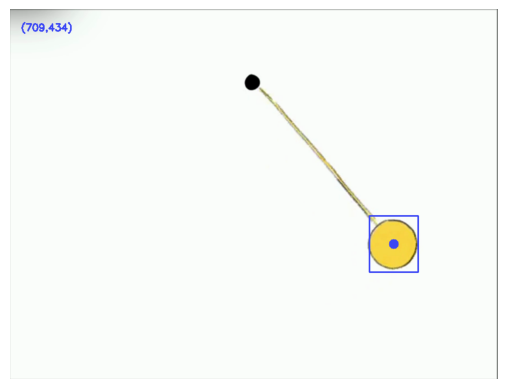

In [7]:
while True:
    frame_num +=1
    flag_read, frame = cap.read()
    if not flag_read:
        break
    flag_track, bbox = tracker.update(frame)
    if flag_track:
        x, y, w, h  = [int(v) for v in bbox]
        center_x    = x + w // 2
        center_y    = y + h // 2
        positions.append([frame_num, center_x, center_y])

        cv2.rectangle(frame, (x, y), (x + w, y + h), (245, 70, 58), 2)
        cv2.circle(frame, (center_x, center_y), int(0.1*min(h,w)), (245, 70, 58), -1)
        cv2.putText(frame, f"({center_x},{center_y})", (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (245, 70, 58), 2)
    else:
        cv2.putText(frame, "Lost", (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (247, 59, 218), 2)

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)  

    clear_output(wait=True)
    plt.imshow(rgb)
    plt.axis('off')
    plt.show()

cap.release()

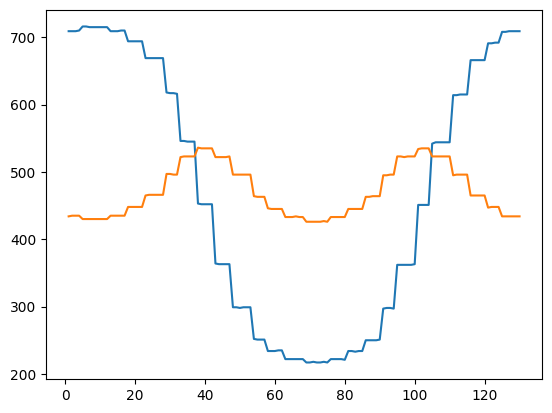

In [8]:
import matplotlib.pyplot as plt
import numpy as np
plt.plot(np.array(positions)[:,0],np.array(positions)[:,1])
plt.plot(np.array(positions)[:,0],np.array(positions)[:,2])


